# NER Text Masker: model comparison
**Pre-trained `dslim/bert-base-NER` vs zero-shot `numind/NuNER_Zero`**

This notebook runs both models on the same data and measures:

1. **Accuracy** on a small hand-labelled set: strict NER scores (exact span + label) and an anonymization score (*masking recall*: is every character of the real name hidden?)
2. **Zero-shot threshold**: how precision and recall move with the confidence threshold
3. **Speed** on CPU and GPU in the same session
4. **Long documents** past BERT's 512-token limit
5. **Flexibility**: custom entity labels
6. **Arabic text**
7. **End-to-end anonymization** of a `.txt` and a `.docx` with all five techniques

The last cell prints a comparison table ready for the report.

**How to run:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. CPU is measured too, so one GPU session gives both. The first run downloads both models, which takes a few minutes.

## 0. Setup
If the next cell changes the `transformers` version and a later import fails, use *Runtime → Restart session* and run again from the top.

In [2]:
!pip install -q gliner faker python-docx

import importlib.metadata as md, torch
for pkg in ["torch", "transformers", "gliner", "faker", "python-docx"]:
    print(f"{pkg:13s}", md.version(pkg))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU only)")

torch         2.14.1+cu130
transformers  5.22.1
gliner        0.2.30
faker         40.52.0
python-docx   1.2.0
GPU: Tesla T4


The anonymization module used by the app. Copy your own version over this cell if your code differs.

In [3]:
%%writefile anonymizer_core.py
"""
anonymizer_core.py - building blocks for the NER Text Masker assignment.

Pipeline:  read file -> detect entities (NER + regex) -> resolve overlaps
           -> build ONE consistent replacement per entity -> replace by offsets
           -> rebuild the .txt / .docx

Models are imported lazily, so everything except detect_bert / detect_zero_shot
can be unit-tested without downloading a model.
"""
import re
import time
import warnings

from faker import Faker

BERT_MODEL = "dslim/bert-base-NER"
ZERO_SHOT_MODEL = "numind/NuNER_Zero"

# ---------------------------------------------------------------- labels
# Every model names its labels differently; the app works with one set.
LABEL_MAP = {
    "PER": "PER", "PERS": "PER", "PERSON": "PER",
    "ORG": "ORG", "ORGANIZATION": "ORG", "ORGANISATION": "ORG", "COMPANY": "ORG",
    "LOC": "LOC", "LOCATION": "LOC", "GPE": "LOC", "CITY": "LOC", "COUNTRY": "LOC",
}
# A zero-shot model reads the label as text, so it gets words, not codes.
ZS_PROMPT = {"PER": "person", "ORG": "organization", "LOC": "location"}


def norm_label(label: str) -> str:
    key = label.strip().upper()
    return LABEL_MAP.get(key, key.replace(" ", "_"))


# ---------------------------------------------------------------- anonymizer
class Anonymizer:
    """Keeps ONE replacement per entity, so the same name is replaced the same way
    everywhere in the document, and short forms ("Ahmed") follow the full name."""

    METHODS = ("mask", "tag", "fake", "partial", "generalize")

    def __init__(self, method="mask", locale="en_US", seed=42):
        if method not in self.METHODS:
            raise ValueError(f"method must be one of {self.METHODS}")
        self.method = method
        self.fake = Faker(locale)
        self.fake.seed_instance(seed)          # reproducible output for the report
        self.mapping, self.counters = {}, {}

    def _make(self, text, label):
        n = self.counters[label] = self.counters.get(label, 0) + 1
        fakers = {"PER": self.fake.name, "ORG": self.fake.company, "LOC": self.fake.city,
                  "EMAIL": self.fake.email, "PHONE": self.fake.phone_number}
        return {
            "mask":       lambda: re.sub(r"\S", "*", text),          # keeps spaces and length
            "tag":        lambda: f"[{label}_{n}]",
            "fake":       lambda: fakers.get(label, lambda: f"[{label}]")(),
            "partial":    lambda: " ".join(w[0] + "*" * (len(w) - 1) for w in text.split()),
            "generalize": lambda: {"PER": "[PERSON]", "ORG": "[COMPANY]",
                                   "LOC": "[PLACE]"}.get(label, f"[{label}]"),
        }[self.method]()

    def _alias(self, key):
        """'Ahmed' after 'Ahmed Ali' -> reuse the matching part of the same replacement."""
        label, name = key
        if label != "PER" or " " in name:
            return None
        for (lab, full), rep in self.mapping.items():
            parts = full.split()
            if lab == "PER" and len(parts) > 1 and name in parts:
                rp = rep.split()
                return rp[min(parts.index(name), len(rp) - 1)]
        return None

    def prepare(self, entities):
        """Pass 1: register every (text, label), longest first, so full names
        get their replacement before their short forms."""
        for text, label in sorted(entities, key=lambda x: -len(x[0])):
            self.replace(text, label)

    def replace(self, text, label):
        key = (label, " ".join(text.lower().split()))
        if key not in self.mapping:
            self.mapping[key] = self._alias(key) or self._make(text, label)
        return self.mapping[key]


# ---------------------------------------------------------------- spans
def resolve_overlaps(ents):
    """Drop duplicates (chunk overlap, regex + NER) and keep the longer span."""
    out = []
    for e in sorted(ents, key=lambda e: (e["start"], -(e["end"] - e["start"]))):
        if out and e["start"] < out[-1]["end"]:
            if e["end"] - e["start"] > out[-1]["end"] - out[-1]["start"]:
                out[-1] = e
            continue
        out.append(e)
    return out


def merge_adjacent(ents, text):
    """Zero-shot models may split one name into neighbouring spans of the same label."""
    out = []
    for e in sorted(ents, key=lambda e: e["start"]):
        if out and e["label"] == out[-1]["label"] and text[out[-1]["end"]:e["start"]] in ("", " "):
            out[-1] = {**out[-1], "end": e["end"], "score": min(out[-1]["score"], e["score"])}
        else:
            out.append(dict(e))
    return out


def split_at_newlines(ents, text):
    """An entity never crosses a line break: a span that does would swallow the
    newline on replacement and break the document's line structure."""
    out = []
    for e in ents:
        pos = e["start"]
        for part in re.split(r"(\r\n|\r|\n)", text[e["start"]:e["end"]]):
            if part and part not in ("\r\n", "\r", "\n") and part.strip():
                lead = len(part) - len(part.lstrip())
                out.append({**e, "start": pos + lead, "end": pos + len(part.rstrip())})
            pos += len(part)
    return out


def apply(text, ents, anon):
    """Replace from the END of the text so earlier offsets stay valid."""
    for e in sorted(ents, key=lambda e: e["start"], reverse=True):
        rep = anon.replace(text[e["start"]:e["end"]], e["label"])
        text = text[:e["start"]] + rep + text[e["end"]:]
    return text


def chunks(text, max_chars=1500, overlap=200):
    """Yield (offset, chunk) windows that never cut a word, with overlap so an
    entity on a boundary is seen whole in at least one window."""
    start = 0
    while start < len(text):
        end = min(start + max_chars, len(text))
        if end < len(text):
            cut = text.rfind(" ", start, end)
            end = cut if cut > start else end
        yield start, text[start:end]
        if end >= len(text):
            break
        nxt = text.find(" ", end - overlap, end)
        start = nxt + 1 if nxt != -1 and nxt + 1 > start else end


# ---------------------------------------------------------------- regex PII
PATTERNS = {
    "EMAIL": r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+",
    "PHONE": r"(?<!\w)\+?\d[\d\s().-]{7,}\d(?!\w)",
}


def regex_entities(text, wanted):
    out = []
    for lab, pat in PATTERNS.items():
        if lab not in wanted:
            continue
        for m in re.finditer(pat, text):
            if lab == "PHONE" and sum(c.isdigit() for c in m.group()) < 9:
                continue                      # skip dates like 2024-10-31
            out.append({"start": m.start(), "end": m.end(), "label": lab, "score": 1.0})
    return out


# ---------------------------------------------------------------- NER models
_models = {}


def load_bert(model_name=BERT_MODEL, device="cpu"):
    key = (model_name, device)
    if key not in _models:
        from transformers import pipeline
        ner = pipeline("token-classification", model=model_name,
                       aggregation_strategy="first",            # whole words, not ##subwords
                       device=0 if str(device).startswith("cuda") else -1)
        # Checkpoints without model_max_length get a huge default; the pipeline then
        # never splits long inputs and BERT crashes past 512 tokens.
        if ner.tokenizer.model_max_length > 100_000:
            ner.tokenizer.model_max_length = ner.model.config.max_position_embeddings
        _models[key] = ner
    return _models[key]


def detect_bert(text, model_name=BERT_MODEL, device="cpu", stride=128):
    """Pre-trained NER. stride= makes the pipeline cover texts longer than 512
    tokens with overlapping windows; manual chunking is the fallback."""
    ner = load_bert(model_name, device)
    try:
        raw = [(0, e) for e in ner(text, stride=stride)]
    except Exception as ex:                                     # slow tokenizer / old version
        warnings.warn(f"stride not supported ({ex}); chunking manually")
        raw = [(off, e) for off, chunk in chunks(text) for e in ner(chunk)]
    return resolve_overlaps([{"start": e["start"] + off, "end": e["end"] + off,
                              "label": norm_label(e["entity_group"]), "score": float(e["score"])}
                             for off, e in raw])


def load_zero_shot(model_name=ZERO_SHOT_MODEL, device="cpu"):
    key = (model_name, device)
    if key not in _models:
        from gliner import GLiNER
        model = GLiNER.from_pretrained(model_name, map_location=device)
        model.to(device)
        model.eval()
        _models[key] = model
    return _models[key]


def detect_zero_shot(text, labels=("PER", "ORG", "LOC"), threshold=0.5,
                     model_name=ZERO_SHOT_MODEL, device="cpu", merge=True):
    """Zero-shot NER (GLiNER family). Labels are free text chosen by the user;
    PER/ORG/LOC are sent as words and NuNER Zero expects lower case."""
    model = load_zero_shot(model_name, device)
    prompts = [ZS_PROMPT.get(l.upper(), l).lower() for l in labels]
    ents = []
    for off, chunk in chunks(text):                 # GLiNER truncates long inputs otherwise
        for e in model.predict_entities(chunk, prompts, threshold=threshold):
            ents.append({"start": e["start"] + off, "end": e["end"] + off,
                         "label": norm_label(e["label"]), "score": float(e["score"])})
    ents = resolve_overlaps(ents)
    return merge_adjacent(ents, text) if merge else ents


def detect(text, model="bert", labels=("PER", "ORG", "LOC"), threshold=0.5,
           regex_labels=("EMAIL", "PHONE"), device="cpu"):
    wanted = {norm_label(l) for l in labels}
    if model == "bert":
        ents = [e for e in detect_bert(text, device=device) if e["label"] in wanted]
    else:
        ents = detect_zero_shot(text, labels, threshold, device=device)
    ents += regex_entities(text, set(regex_labels))
    return resolve_overlaps(split_at_newlines(ents, text))


def count_params(model):
    """Millions of parameters of a pipeline or a GLiNER model."""
    module = getattr(model, "model", model)
    if not hasattr(module, "parameters"):
        module = model
    return sum(p.numel() for p in module.parameters()) / 1e6


# ---------------------------------------------------------------- .txt
def read_txt(path):
    """newline='' keeps \\r\\n exactly; cp1256 covers Arabic files saved by old Windows tools."""
    for enc in ("utf-8-sig", "cp1256", "latin-1"):
        try:
            with open(path, encoding=enc, newline="") as f:
                return f.read(), enc
        except UnicodeDecodeError:
            continue


def write_txt(path, text, encoding="utf-8"):
    with open(path, "w", encoding=encoding, newline="") as f:
        f.write(text)


def anonymize_txt(src, dst, anon, **detect_kw):
    text, enc = read_txt(src)
    ents = detect(text, **detect_kw)
    anon.prepare([(text[e["start"]:e["end"]], e["label"]) for e in ents])
    write_txt(dst, apply(text, ents, anon), "utf-8" if enc == "latin-1" else enc.replace("-sig", ""))
    return text, ents


# ---------------------------------------------------------------- .docx
def all_runs(par):
    """paragraph.runs skips text inside hyperlinks - include those runs too."""
    from docx.text.hyperlink import Hyperlink
    for item in par.iter_inner_content():
        yield from (item.runs if isinstance(item, Hyperlink) else [item])


def iter_paragraphs(doc):
    """Body, tables (nested; a merged cell only once), headers and footers."""
    seen = set()

    def walk(container):
        for p in container.paragraphs:
            if p._p not in seen:
                seen.add(p._p)
                yield p
        for t in container.tables:
            for row in t.rows:
                for cell in row.cells:
                    yield from walk(cell)

    yield from walk(doc)
    for s in doc.sections:
        for hf in (s.header, s.footer):
            if not hf.is_linked_to_previous:
                yield from walk(hf)


def replace_in_runs(runs, start, end, rep):
    """Replace paragraph-level [start, end) even when Word split it over several runs.
    The replacement takes the formatting of the run it starts in."""
    pos, first = 0, True
    for r in runs:
        t = r.text
        s, e = pos, pos + len(t)
        pos = e
        if e <= start or s >= end:
            continue
        a, b = max(start, s) - s, min(end, e) - s
        r.text = t[:a] + (rep if first else "") + t[b:]
        first = False


def anonymize_docx(src, dst, anon, **detect_kw):
    from docx import Document
    doc = Document(src)
    found = []                                            # pass 1: detect everything
    for par in iter_paragraphs(doc):
        runs = list(all_runs(par))
        text = "".join(r.text for r in runs)
        found.append((runs, text, detect(text, **detect_kw) if text.strip() else []))
    anon.prepare([(t[e["start"]:e["end"]], e["label"]) for _, t, ents in found for e in ents])
    for runs, text, ents in found:                        # pass 2: replace
        for e in sorted(ents, key=lambda e: e["start"], reverse=True):
            replace_in_runs(runs, e["start"], e["end"],
                            anon.replace(text[e["start"]:e["end"]], e["label"]))
    doc.save(dst)
    return found


# ---------------------------------------------------------------- evaluation
def build_gold(raw):
    """raw = [(sentence, [(entity_text, label[, occurrence]), ...]), ...] -> texts, gold spans."""
    texts, gold = [], []
    for sent, ents in raw:
        spans = []
        for item in ents:
            ent, lab, occ = (item + (0,))[:3]
            i = -1
            for _ in range(occ + 1):
                i = sent.find(ent, i + 1)
            if i < 0:
                raise ValueError(f"{ent!r} not found in {sent!r}")
            spans.append({"start": i, "end": i + len(ent), "label": lab})
        texts.append(sent)
        gold.append(sorted(spans, key=lambda e: e["start"]))
    return texts, gold


def _keep(ents, labels):
    return {(e["start"], e["end"], e["label"]) for e in ents if labels is None or e["label"] in labels}


def exact_scores(preds, golds, labels=None):
    """Strict NER metric: span AND label must match exactly (micro-averaged)."""
    tp = fp = fn = 0
    for p, g in zip(preds, golds):
        P, G = _keep(p, labels), _keep(g, labels)
        tp, fp, fn = tp + len(P & G), fp + len(P - G), fn + len(G - P)
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {"Precision": round(prec, 3), "Recall": round(rec, 3), "F1": round(f1, 3),
            "TP": tp, "FP": fp, "FN": fn}


def masking_scores(preds, golds, texts):
    """Anonymization view: is every character of the real entity hidden, whatever
    label the model gave it? A wrong label still hides a name; a missed word leaks it."""
    full = part = leak = 0
    for p, g, t in zip(preds, golds, texts):
        for e in g:
            chars = [i for i in range(e["start"], e["end"]) if not t[i].isspace()]
            hit = sum(any(x["start"] <= i < x["end"] for x in p) for i in chars)
            full += hit == len(chars)
            part += 0 < hit < len(chars)
            leak += hit == 0
    total = full + part + leak
    return {"Masking recall": round(full / total, 3) if total else 0.0,
            "Partly leaked": part, "Fully leaked": leak}


def benchmark(fn, texts, warmup=1):
    """Seconds per 1000 words; warm-up calls (model load, CUDA init) are not timed."""
    for t in texts[:warmup]:
        fn(t)
    try:
        import torch
        sync = torch.cuda.synchronize if torch.cuda.is_available() else (lambda: None)
    except ImportError:
        sync = lambda: None
    words = sum(len(t.split()) for t in texts)
    sync()
    t0 = time.perf_counter()
    for t in texts:
        fn(t)
    sync()
    return (time.perf_counter() - t0) / words * 1000

Writing anonymizer_core.py


In [4]:
import importlib, json, time, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import anonymizer_core as ac
importlib.reload(ac)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

DEVICES = ["cpu"] + (["cuda"] if torch.cuda.is_available() else [])
DEV = DEVICES[-1]                      # main device for the accuracy runs
LABELS = ("PER", "ORG", "LOC")
ZS_THRESHOLD = 0.5
MODELS = {"BERT": "bert", "NuNER Zero": "zero"}

# Chart style (validated categorical colours; text stays in ink colours)
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]

def style(ax, title, ylabel):
    ax.set_facecolor(SURF); ax.figure.set_facecolor(SURF)
    ax.set_title(title, loc="left", color=INK, fontsize=12, pad=12)
    ax.set_ylabel(ylabel, color=INK2)
    ax.tick_params(colors=INK2, length=0)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

COUNTS = ["TP", "FP", "FN", "Partly leaked", "Fully leaked"]

def scores_df(rows):
    # dict of {model: {metric: value}} -> table with counts shown as integers
    df = pd.DataFrame(rows).T.astype(float)
    for c in COUNTS:
        if c in df:
            df[c] = df[c].astype(int)
    return df

def predict(kind, texts, device=DEV, labels=LABELS, threshold=ZS_THRESHOLD, merge=True):
    # Raw model output (no regex layer): this section evaluates the NER models only.
    if kind == "bert":
        return [[e for e in ac.detect_bert(t, device=device) if e["label"] in labels] for t in texts]
    return [ac.detect_zero_shot(t, labels, threshold=threshold, device=device, merge=merge) for t in texts]

print("Devices:", DEVICES)

Devices: ['cpu', 'cuda']


## 1. Load the models
Load time on the first run includes the download.

In [5]:
info = {}
for name, kind in MODELS.items():
    t0 = time.perf_counter()
    model = ac.load_bert(device=DEV) if kind == "bert" else ac.load_zero_shot(device=DEV)
    info[name] = {"Load time (s)": round(time.perf_counter() - t0, 1),
                  "Parameters (M)": round(ac.count_params(model), 1)}
LOAD = pd.DataFrame(info).T
LOAD

config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

... (6 outputs left out)

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

,Load time (s),Parameters (M)
BERT,36.7,107.7
NuNER Zero,77.3,448.9


## 2. Hand-labelled test set
18 English sentences, built to include the hard cases on purpose:
ambiguous names (*Jordan*, *Washington*, *Paris*), person names nested inside organizations (*Johns Hopkins University*),
locations nested inside organizations (*Damascus Water Authority*), all-lowercase text, Arabic names written in English,
medical and legal sentences, and one sentence with no entities at all (only an e-mail and a phone number) to count false positives.

**Annotation rules:** titles (*Dr.*, *Mr.*, *Judge*) are not part of a PER span; a city inside an organization's name belongs to the ORG.
The set is small, so treat the numbers as indicative and say so in the report.

In [6]:
RAW = [
    ("Ahmed Al-Khatib joined Microsoft in Seattle last March.",
     [("Ahmed Al-Khatib", "PER"), ("Microsoft", "ORG"), ("Seattle", "LOC")]),
    ("Dr. Sarah Johnson from Johns Hopkins University presented the results in Baltimore.",
     [("Sarah Johnson", "PER"), ("Johns Hopkins University", "ORG"), ("Baltimore", "LOC")]),
    ("The contract between Siemens and the Damascus Water Authority was signed in Berlin.",
     [("Siemens", "ORG"), ("Damascus Water Authority", "ORG"), ("Berlin", "LOC")]),
    ("Michael Jordan visited Jordan to meet officials from the United Nations.",
     [("Michael Jordan", "PER"), ("Jordan", "LOC", 1), ("United Nations", "ORG")]),
    ("Apple released a new phone, and Tim Cook said sales in China were strong.",
     [("Apple", "ORG"), ("Tim Cook", "PER"), ("China", "LOC")]),
    ("Fatima Hassan and her brother Omar moved from Aleppo to Toronto in 2019.",
     [("Fatima Hassan", "PER"), ("Omar", "PER"), ("Aleppo", "LOC"), ("Toronto", "LOC")]),
    ("Please send the signed form to maria.lopez@example.com or call +1 415 555 0134.",
     []),
    ("Goldman Sachs hired Priya Raman as head of its London office.",
     [("Goldman Sachs", "ORG"), ("Priya Raman", "PER"), ("London", "LOC")]),
    ("The patient, John Smith, was transferred from St. Mary's Hospital in Boston to the Mayo Clinic.",
     [("John Smith", "PER"), ("St. Mary's Hospital", "ORG"), ("Boston", "LOC"), ("Mayo Clinic", "ORG")]),
    ("Paris Hilton was spotted in Paris near the Eiffel Tower.",
     [("Paris Hilton", "PER"), ("Paris", "LOC", 1), ("Eiffel Tower", "LOC")]),
    ("lina khoury works for amazon in dubai.",
     [("lina khoury", "PER"), ("amazon", "ORG"), ("dubai", "LOC")]),
    ("Khalid bin Saeed, CEO of Gulf Logistics Group, flew from Riyadh to Cairo.",
     [("Khalid bin Saeed", "PER"), ("Gulf Logistics Group", "ORG"), ("Riyadh", "LOC"), ("Cairo", "LOC")]),
    ("Washington signed the bill in Washington before leaving for New York.",
     [("Washington", "PER"), ("Washington", "LOC", 1), ("New York", "LOC")]),
    ("The European Central Bank raised rates, according to Christine Lagarde.",
     [("European Central Bank", "ORG"), ("Christine Lagarde", "PER")]),
    ("Nour and Karim met at the University of Damascus cafeteria.",
     [("Nour", "PER"), ("Karim", "PER"), ("University of Damascus", "ORG")]),
    ("Last week, Tesla opened a factory near Austin, Texas.",
     [("Tesla", "ORG"), ("Austin", "LOC"), ("Texas", "LOC")]),
    ("Judge Emily Carter dismissed the case brought by Northwind Traders against Contoso Ltd.",
     [("Emily Carter", "PER"), ("Northwind Traders", "ORG"), ("Contoso Ltd", "ORG")]),
    ("Mr. Yusuf Demir, a resident of Istanbul, banks with Ziraat Bank.",
     [("Yusuf Demir", "PER"), ("Istanbul", "LOC"), ("Ziraat Bank", "ORG")]),
]
TEXTS, GOLD = ac.build_gold(RAW)
print(len(TEXTS), "sentences,", sum(map(len, GOLD)), "entities")
pd.Series([e["label"] for g in GOLD for e in g]).value_counts().rename("entities")

18 sentences, 53 entities


,entities
LOC,19
PER,17
ORG,17


In [7]:
print( GOLD)
print(TEXTS)

[[{'start': 0, 'end': 15, 'label': 'PER'}, {'start': 23, 'end': 32, 'label': 'ORG'}, {'start': 36, 'end': 43, 'label': 'LOC'}], [{'start': 4, 'end': 17, 'label': 'PER'}, {'start': 23, 'end': 47, 'label': 'ORG'}, {'start': 73, 'end': 82, 'label': 'LOC'}], [{'start': 21, 'end': 28, 'label': 'ORG'}, {'start': 37, 'end': 61, 'label': 'ORG'}, {'start': 76, 'end': 82, 'label': 'LOC'}], [{'start': 0, 'end': 14, 'label': 'PER'}, {'start': 23, 'end': 29, 'label': 'LOC'}, {'start': 57, 'end': 71, 'label': 'ORG'}], [{'start': 0, 'end': 5, 'label': 'ORG'}, {'start': 32, 'end': 40, 'label': 'PER'}, {'start': 55, 'end': 60, 'label': 'LOC'}], [{'start': 0, 'end': 13, 'label': 'PER'}, {'start': 30, 'end': 34, 'label': 'PER'}, {'start': 46, 'end': 52, 'label': 'LOC'}, {'start': 56, 'end': 63, 'label': 'LOC'}], [], [{'start': 0, 'end': 13, 'label': 'ORG'}, {'start': 20, 'end': 31, 'label': 'PER'}, {'start': 47, 'end': 53, 'label': 'LOC'}], [{'start': 13, 'end': 23, 'label': 'PER'}, {'start': 46, 'end': 

In [8]:
PRED = {name: predict(kind, TEXTS) for name, kind in MODELS.items()}
print("done")

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


done


## 3. Accuracy
* **Precision / Recall / F1 (exact):** the standard NER metric. A span counts only if its boundaries *and* label match the gold exactly.
* **Masking recall:** the share of gold entities whose every character is covered by some prediction, whatever its label.
  This is what matters for anonymization: labelling *Jordan* as PER instead of LOC still hides it, but missing *Johnson* in *Sarah Johnson* leaks a name.

In [9]:
ACC = scores_df({name: {**ac.exact_scores(PRED[name], GOLD),
                        **ac.masking_scores(PRED[name], GOLD, TEXTS)} for name in MODELS})
ACC

,Precision,Recall,F1,TP,FP,FN,Masking recall,Partly leaked,Fully leaked
BERT,0.940,0.887,0.913,47,3,6,0.943,0,3
NuNER Zero,0.907,0.925,0.916,49,5,4,1.000,0,0


In [10]:
PER_LABEL = pd.DataFrame({name: {lab: ac.exact_scores(PRED[name], GOLD, labels={lab})["F1"] for lab in LABELS}
                          for name in MODELS}).T
PER_LABEL.columns = [f"F1 {c}" for c in PER_LABEL.columns]
PER_LABEL

,F1 PER,F1 ORG,F1 LOC
BERT,0.938,0.903,0.900
NuNER Zero,0.765,1.000,0.974


### Error analysis
Every miss and false positive per model. These rows are the best material for the report's *Challenges* section.

In [11]:
def errors(preds, golds, texts):
    rows = []
    for i, (p, g, t) in enumerate(zip(preds, golds, texts)):
        P = {(e["start"], e["end"], e["label"]) for e in p}
        G = {(e["start"], e["end"], e["label"]) for e in g}
        for s, e, lab in sorted(G - P):
            got = [f'{t[x["start"]:x["end"]]} / {x["label"]}' for x in p if x["start"] < e and x["end"] > s]
            rows.append({"sentence": i, "type": "wrong span or label" if got else "missed",
                         "gold": f"{t[s:e]} / {lab}", "predicted": ", ".join(got) or "-"})
        for s, e, lab in sorted(P - G):
            if not any(x["start"] < e and x["end"] > s for x in g):
                rows.append({"sentence": i, "type": "false positive", "gold": "-", "predicted": f"{t[s:e]} / {lab}"})
    return pd.DataFrame(rows, columns=["sentence", "type", "gold", "predicted"])

ERRORS = {name: errors(PRED[name], GOLD, TEXTS) for name in MODELS}
for name, df in ERRORS.items():
    print(f"\n=== {name}: {len(df)} errors ===")
    display(df)


=== BERT: 6 errors ===


,sentence,type,gold,predicted
0,8,wrong span or label,St. Mary's Hospital / ORG,St. Mary's Hospital / LOC
1,8,wrong span or label,Mayo Clinic / ORG,Mayo Clinic / LOC
2,10,missed,lina khoury / PER,-
3,10,missed,amazon / ORG,-
4,10,missed,dubai / LOC,-
5,12,wrong span or label,Washington / PER,Washington / LOC



=== NuNER Zero: 5 errors ===


,sentence,type,gold,predicted
0,1,wrong span or label,Sarah Johnson / PER,Dr. Sarah Johnson / PER
1,6,false positive,-,maria.lopez@ / PER
2,12,wrong span or label,Washington / PER,Washington / LOC
3,16,wrong span or label,Emily Carter / PER,Judge Emily Carter / PER
4,17,wrong span or label,Yusuf Demir / PER,Mr. Yusuf Demir / PER


## 4. Zero-shot confidence threshold
NuNER Zero predicts once at a low threshold (0.1); the other thresholds filter those scores.
This gives the same result as re-running at each threshold, because GLiNER's greedy decoding keeps the highest-scoring span first.

Best F1 at threshold 0.8; highest threshold that keeps the best masking recall: 0.9


,Precision,Recall,F1,Masking recall,Partly leaked,Fully leaked
threshold,,,,,,
0.1,0.839,0.887,0.862,1.0,0,0
0.2,0.855,0.887,0.870,1.0,0,0
0.3,0.855,0.887,0.870,1.0,0,0
0.4,0.887,0.887,0.887,1.0,0,0
0.5,0.907,0.925,0.916,1.0,0,0
0.6,0.907,0.925,0.916,1.0,0,0
0.7,0.907,0.925,0.916,1.0,0,0
0.8,0.909,0.943,0.926,1.0,0,0
0.9,0.909,0.943,0.926,1.0,0,0


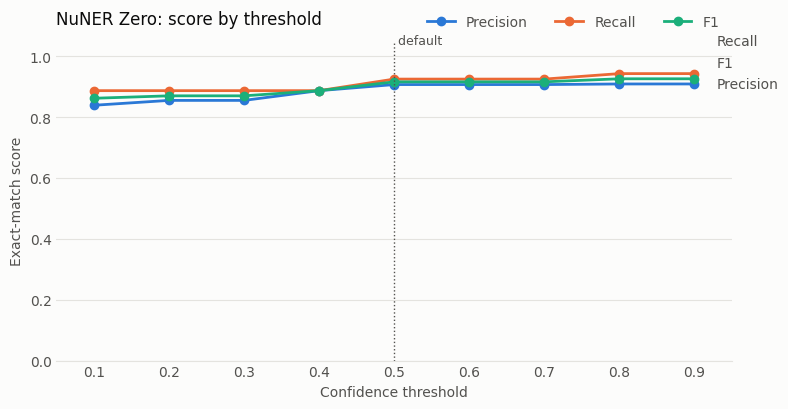

In [12]:
LOW = predict("zero", TEXTS, threshold=0.1, merge=False)
rows = {}
for t in np.round(np.arange(0.1, 0.91, 0.1), 1):
    preds = [ac.merge_adjacent([e for e in p if e["score"] >= t], txt) for p, txt in zip(LOW, TEXTS)]
    s = ac.exact_scores(preds, GOLD)
    rows[t] = {"Precision": s["Precision"], "Recall": s["Recall"], "F1": s["F1"],
               **ac.masking_scores(preds, GOLD, TEXTS)}
SWEEP = scores_df(rows)
SWEEP.index.name = "threshold"

best_f1 = SWEEP["F1"].idxmax()
safe = SWEEP[SWEEP["Masking recall"] >= SWEEP["Masking recall"].max() - 1e-9].index.max()
print(f"Best F1 at threshold {best_f1}; highest threshold that keeps the best masking recall: {safe}")
display(SWEEP)

fig, ax = plt.subplots(figsize=(8, 4.2))
cols = ["Precision", "Recall", "F1"]
for col, color in zip(cols, SERIES):
    ax.plot(SWEEP.index, SWEEP[col], color=color, lw=2, marker="o", ms=6, label=col)
# direct labels at the line ends, pushed apart so close values don't overlap
ends = sorted(((SWEEP[c].iloc[-1], c) for c in cols))
ys = []
for v, _ in ends:
    ys.append(max(v, ys[-1] + 0.07) if ys else v)
for (v, c), y in zip(ends, ys):
    ax.annotate(c, (SWEEP.index[-1], v), xytext=(SWEEP.index[-1] + 0.03, y), textcoords="data",
                va="center", color=INK2, fontsize=10, annotation_clip=False)
ax.axvline(ZS_THRESHOLD, color=INK2, lw=1, ls=":")
ax.text(ZS_THRESHOLD, 1.03, " default", color=INK2, fontsize=9, va="bottom")
ax.set_ylim(0, 1.05); ax.set_xlim(0.05, 0.95)
ax.set_xlabel("Confidence threshold", color=INK2)
style(ax, "NuNER Zero: score by threshold", "Exact-match score")
ax.legend(frameon=False, ncol=3, loc="lower right", bbox_to_anchor=(1, 1.0), labelcolor=INK2)
plt.tight_layout(); plt.show()

## 5. Speed: CPU vs GPU
Seconds per 1,000 words over four ~700-word documents. The first call (model load, CUDA start-up) is a warm-up and is not timed.

2460 words per run


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT        CPU  3.603 s / 1000 words


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

NuNER Zero  CPU  16.053 s / 1000 words
BERT        CUDA 0.175 s / 1000 words
NuNER Zero  CUDA 0.520 s / 1000 words


,CPU,CUDA
BERT,3.603,0.175
NuNER Zero,16.053,0.520


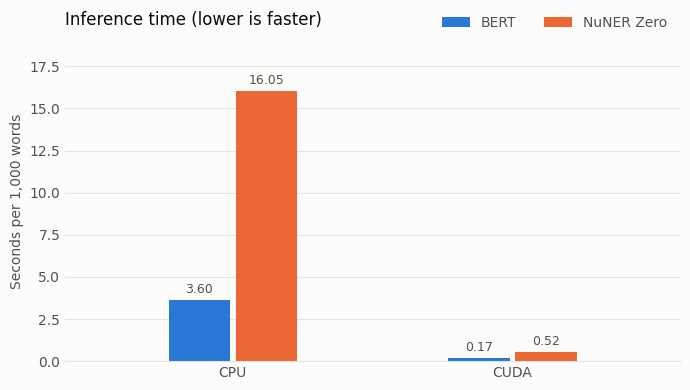

In [13]:
DOC = " ".join(TEXTS)
BENCH = [" ".join([DOC] * 3)] * 4
print(f"{sum(len(t.split()) for t in BENCH)} words per run")

SPEED = {}
for dev in DEVICES:
    for name, kind in MODELS.items():
        fn = (lambda t, d=dev: ac.detect_bert(t, device=d)) if kind == "bert" else \
             (lambda t, d=dev: ac.detect_zero_shot(t, LABELS, device=d))
        SPEED[(name, dev.upper())] = round(ac.benchmark(fn, BENCH), 3)
        print(f"{name:11s} {dev.upper():4s} {SPEED[(name, dev.upper())]:.3f} s / 1000 words")

SPEED_DF = pd.Series(SPEED).unstack()
display(SPEED_DF)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(SPEED_DF.columns)); w = 0.22
for i, (name, color) in enumerate(zip(SPEED_DF.index, SERIES)):
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), SPEED_DF.loc[name], w, color=color, label=name)
    ax.bar_label(bars, fmt="%.2f", padding=3, color=INK2, fontsize=9)
ax.set_xticks(x, SPEED_DF.columns); ax.set_xlim(-0.6, len(x) - 0.4)
ax.set_ylim(0, SPEED_DF.values.max() * 1.18)
style(ax, "Inference time (lower is faster)", "Seconds per 1,000 words")
ax.legend(frameon=False, ncol=2, loc="lower right", bbox_to_anchor=(1, 1.0), labelcolor=INK2)
plt.tight_layout(); plt.show()

## 6. Long documents (past the 512-token limit)
Names are planted at the very end of a long text. The *naive* rows call each model directly, without the fixes in `anonymizer_core`
(`stride=` for BERT, chunking for NuNER Zero), to show what goes wrong; the *fixed* rows use the module.

In [14]:
PLANTED = [("Zainab Haddad", "PER"), ("Orion Analytics", "ORG"), ("Homs", "LOC")]
LONG = (" ".join(TEXTS) + " ") * 8 + "The final report was signed by Zainab Haddad of Orion Analytics in Homs."
tail = len(LONG) - 80
n_tokens = len(ac.load_bert(device=DEV).tokenizer(LONG)["input_ids"])
print(f"{len(LONG.split())} words, {n_tokens} BERT tokens (limit 512)")

def planted_found(ents):
    got = {(LONG[e["start"]:e["end"]], e["label"]) for e in ents if e["start"] >= tail}
    return f"{sum(p in got for p in PLANTED)}/{len(PLANTED)}"

rows = []
ner = ac.load_bert(device=DEV)
cut = ner.tokenizer(LONG, return_offsets_mapping=True)["offset_mapping"][510][1]   # end of token 512
try:
    naive = [{"start": e["start"], "end": e["end"], "label": ac.norm_label(e["entity_group"])} for e in ner(LONG)]
    last = max((e["end"] for e in naive), default=0)
    rows.append(("BERT", "naive (no stride)", planted_found(naive),
                 f"nothing found after character {cut} of {len(LONG)}: input truncated at 512 tokens" if last <= cut else ""))
except Exception as ex:
    rows.append(("BERT", "naive (no stride)", "crashed", f"{type(ex).__name__}: {str(ex)[:90]}"))
rows.append(("BERT", "fixed (stride=128)", planted_found(ac.detect_bert(LONG, device=DEV)), ""))

zs = ac.load_zero_shot(device=DEV)
try:
    naive = [{"start": e["start"], "end": e["end"], "label": ac.norm_label(e["label"])}
             for e in zs.predict_entities(LONG, ["person", "organization", "location"], threshold=ZS_THRESHOLD)]
    found = planted_found(naive)
    rows.append(("NuNER Zero", "naive (one call)", found,
                 f"input truncated to {zs.config.max_len} words" if found == "0/3" else ""))
except Exception as ex:
    rows.append(("NuNER Zero", "naive (one call)", "crashed", f"{type(ex).__name__}: {str(ex)[:90]}"))
rows.append(("NuNER Zero", "fixed (chunks + overlap)", planted_found(ac.detect_zero_shot(LONG, device=DEV)), ""))

LONGDOC = pd.DataFrame(rows, columns=["model", "method", "planted entities found", "note"])
LONGDOC

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (2262 > 512). Running this sequence through the model will result in indexing errors


1653 words, 2262 BERT tokens (limit 512)


,model,method,planted entities found,note
0,BERT,naive (no stride),0/3,nothing found after character 2313 of 10160: input truncated at 512 tokens
1,BERT,fixed (stride=128),3/3,
2,NuNER Zero,naive (one call),0/3,input truncated to 384 words
3,NuNER Zero,fixed (chunks + overlap),3/3,


## 7. Flexibility: custom entity labels
BERT can only return the four CoNLL labels it was trained on (PER, ORG, LOC, MISC). NuNER Zero takes any label written as text.

In [15]:
FLEX = ("On 12 March 2024, Dr. Leila Mansour, chief cardiologist at Al-Noor Hospital in Amman, "
        "diagnosed the patient Rami Saleh with type 2 diabetes and billed $1,200 to his insurer, Arab Shield. "
        "His passport number is N1234567.")
CUSTOM = ["person", "organization", "location", "date", "job title", "medical condition", "money", "passport number"]

def as_table(ents, text):
    return pd.DataFrame([{"text": text[e["start"]:e["end"]], "label": e["label"], "score": round(e["score"], 2)}
                         for e in ents])

print("BERT (fixed label set):"); display(as_table(ac.detect_bert(FLEX, device=DEV), FLEX))
print("NuNER Zero (custom labels):"); display(as_table(ac.detect_zero_shot(FLEX, CUSTOM, threshold=0.3, device=DEV), FLEX))

BERT (fixed label set):


,text,label,score
0,Leila Mansour,PER,1.00
1,Al-Noor Hospital,LOC,1.00
2,Amman,LOC,1.00
3,Rami Saleh,PER,1.00
4,Arab Shield,ORG,0.99


NuNER Zero (custom labels):


,text,label,score
0,12 March 2024,DATE,0.98
1,Dr. Leila Mansour,PER,0.97
2,chief cardiologist,JOB_TITLE,0.51
3,Al-Noor Hospital,ORG,1.00
4,Amman,LOC,1.00
5,Rami Saleh,PER,1.00
6,type 2 diabetes,MEDICAL_CONDITION,1.00
7,"$1,200",MONEY,0.99
8,Arab Shield,ORG,0.99
9,N1234567,PASSPORT_NUMBER,1.00


## 8. Arabic text
Both required models were trained on English. The optional cell after this one tries two multilingual or Arabic models;
it is wrapped in `try`, so a failed download does not stop the notebook.

In [23]:
RAW_AR = [
    ("التقى أحمد الخطيب بمدير شركة سيمنز في دمشق.",
     [("أحمد الخطيب", "PER"), ("سيمنز", "ORG"), ("دمشق", "LOC")]),
    ("تعمل فاطمة حسن في جامعة حلب منذ عام 2019.",
     [("فاطمة حسن", "PER"), ("جامعة حلب", "ORG")]),
    ("سافر عمر من الرياض إلى القاهرة لحضور مؤتمر الأمم المتحدة.",
     [("عمر", "PER"), ("الرياض", "LOC"), ("القاهرة", "LOC"), ("الأمم المتحدة", "ORG")]),
]
TEXTS_AR, GOLD_AR = ac.build_gold(RAW_AR)
PRED_AR = {name: predict(kind, TEXTS_AR) for name, kind in MODELS.items()}
ARABIC = scores_df({name: {**ac.exact_scores(PRED_AR[name], GOLD_AR),
                           **ac.masking_scores(PRED_AR[name], GOLD_AR, TEXTS_AR)} for name in MODELS})
display(ARABIC)
print ('------')
print (PRED_AR['NuNER Zero'])
print ('------')
for name in MODELS:
    print(name, [[f'{t[e["start"]:e["end"]]}/{e["label"]}' for e in p] for p, t in zip(PRED_AR[name], TEXTS_AR)])

,Precision,Recall,F1,TP,FP,FN,Masking recall,Partly leaked,Fully leaked
BERT,0.000,0.000,0.000,0,2,9,0.0,0,9
NuNER Zero,0.778,0.778,0.778,7,2,2,1.0,0,0


------
[[{'start': 6, 'end': 17, 'label': 'PER', 'score': 0.9978092312812805}, {'start': 24, 'end': 34, 'label': 'ORG', 'score': 0.9390289783477783}, {'start': 38, 'end': 42, 'label': 'LOC', 'score': 0.9975742697715759}], [{'start': 5, 'end': 14, 'label': 'PER', 'score': 0.8791868090629578}, {'start': 18, 'end': 27, 'label': 'LOC', 'score': 0.8665140271186829}], [{'start': 5, 'end': 8, 'label': 'PER', 'score': 0.982653796672821}, {'start': 12, 'end': 18, 'label': 'LOC', 'score': 0.9969106316566467}, {'start': 23, 'end': 30, 'label': 'LOC', 'score': 0.9985911250114441}, {'start': 43, 'end': 56, 'label': 'ORG', 'score': 0.947071373462677}]]
------
BERT [[], ['تعمل/ORG'], ['سافر/ORG']]
NuNER Zero [['أحمد الخطيب/PER', 'شركة سيمنز/ORG', 'دمشق/LOC'], ['فاطمة حسن/PER', 'جامعة حلب/LOC'], ['عمر/PER', 'الرياض/LOC', 'القاهرة/LOC', 'الأمم المتحدة/ORG']]


In [17]:
# Optional: models that know Arabic (check the names on huggingface.co if a download fails)
EXTRA = {"GLiNER multilingual": ("zero", "urchade/gliner_multi-v2.1"),
         "CAMeLBERT Arabic NER": ("bert", "CAMeL-Lab/bert-base-arabic-camelbert-mix-ner")}
for name, (kind, repo) in EXTRA.items():
    try:
        if kind == "zero":
            preds = [ac.detect_zero_shot(t, LABELS, model_name=repo, device=DEV) for t in TEXTS_AR]
        else:
            preds = [[e for e in ac.detect_bert(t, model_name=repo, device=DEV) if e["label"] in LABELS] for t in TEXTS_AR]
        row = {**ac.exact_scores(preds, GOLD_AR), **ac.masking_scores(preds, GOLD_AR, TEXTS_AR)}
        ARABIC = pd.concat([ARABIC, scores_df({name: row})])
    except Exception as ex:
        print(f"{name}: skipped ({type(ex).__name__}: {str(ex)[:100]})")
ARABIC

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

... (7 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

,Precision,Recall,F1,TP,FP,FN,Masking recall,Partly leaked,Fully leaked
BERT,0.000,0.000,0.000,0,2,9,0.000,0,9
NuNER Zero,0.778,0.778,0.778,7,2,2,1.000,0,0
GLiNER multilingual,0.889,0.889,0.889,8,1,1,1.000,0,0
CAMeLBERT Arabic NER,0.889,0.889,0.889,8,1,1,0.889,1,0


## 9. End-to-end anonymization
The full app pipeline (NER + e-mail/phone regex, consistent replacements, offset-safe rebuild) on a `.txt` with Windows line endings
and on a `.docx` with a name split across formatted runs, a table with a merged cell, and a header.

In [18]:
SAMPLE = ("Ahmed Al-Khatib met Sara Haddad at Microsoft in Seattle.\r\n"
          "Later, Ahmed e-mailed sara.haddad@example.com and called +963 944 123 456.\r\n"
          "Sara replied from Damascus on 2024-10-31.\r\n")
with open("sample.txt", "w", encoding="utf-8", newline="") as f:
    f.write(SAMPLE)

rows = []
for name, kind in MODELS.items():
    for method in ac.Anonymizer.METHODS:
        out = f"sample_{kind}_{method}.txt"
        ac.anonymize_txt("sample.txt", out, ac.Anonymizer(method), model=kind, device=DEV)
        text, _ = ac.read_txt(out)
        rows.append({"model": name, "method": method, "CRLF kept": text.count("\r\n") == 3,
                     "output": text.replace("\r\n", " ⏎ ")})
print("Original:", SAMPLE.replace("\r\n", " ⏎ "))
TXT_DEMO = pd.DataFrame(rows)
TXT_DEMO

Original: Ahmed Al-Khatib met Sara Haddad at Microsoft in Seattle. ⏎ Later, Ahmed e-mailed sara.haddad@example.com and called +963 944 123 456. ⏎ Sara replied from Damascus on 2024-10-31. ⏎ 


,model,method,CRLF kept,output
0,BERT,mask,True,"***** ********* met **** ****** at ********* in *******. ⏎ Later, ***** e-mailed *********************** and called **** *** *** ***. ⏎ ..."
1,BERT,tag,True,"[PER_1] met [PER_2] at [ORG_1] in [LOC_2]. ⏎ Later, [PER_1] e-mailed [EMAIL_1] and called [PHONE_1]. ⏎ [PER_2] replied from [LOC_1] on 2..."
2,BERT,fake,True,"Alyssa Gonzalez met Kimberly Robinson at Ramirez, Booth and Blake in Ericmouth. ⏎ Later, Alyssa e-mailed johnsonjoshua@example.org and c..."
3,BERT,partial,True,"A**** A******** met S*** H***** at M******** in S******. ⏎ Later, A**** e-mailed s********************** and called +*** 9** 1** 4**. ⏎ ..."
4,BERT,generalize,True,"[PERSON] met [PERSON] at [COMPANY] in [PLACE]. ⏎ Later, [PERSON] e-mailed [EMAIL] and called [PHONE]. ⏎ [PERSON] replied from [PLACE] on..."
5,NuNER Zero,mask,True,"***** ********* met **** ****** at ********* in *******. ⏎ Later, Ahmed e-mailed *********************** and called **** *** *** ***. ⏎ ..."
6,NuNER Zero,tag,True,"[PER_1] met [PER_2] at [ORG_1] in [LOC_2]. ⏎ Later, Ahmed e-mailed [EMAIL_1] and called [PHONE_1]. ⏎ Sara replied from [LOC_1] on 2024-1..."
7,NuNER Zero,fake,True,"Alyssa Gonzalez met Kimberly Robinson at Ramirez, Booth and Blake in Ericmouth. ⏎ Later, Ahmed e-mailed johnsonjoshua@example.org and ca..."
8,NuNER Zero,partial,True,"A**** A******** met S*** H***** at M******** in S******. ⏎ Later, Ahmed e-mailed s********************** and called +*** 9** 1** 4**. ⏎ ..."
9,NuNER Zero,generalize,True,"[PERSON] met [PERSON] at [COMPANY] in [PLACE]. ⏎ Later, Ahmed e-mailed [EMAIL] and called [PHONE]. ⏎ Sara replied from [PLACE] on 2024-1..."


In [19]:
from docx import Document

d = Document()
d.sections[0].header.paragraphs[0].text = "Confidential: Ahmed Al-Khatib"
p = d.add_paragraph()
r = p.add_run("Ah"); r.bold = True            # one name split over two runs with different formatting
p.add_run("med Al-Khatib works at ")
r = p.add_run("Microsoft"); r.italic = True
p.add_run(" in Seattle.")
t = d.add_table(rows=2, cols=2)
t.cell(0, 0).text = "Sara Haddad visited Damascus."
t.cell(0, 0).merge(t.cell(0, 1))              # merged cell: python-docx returns it twice
t.cell(1, 0).text = "Contact: sara.haddad@example.com"
t.cell(1, 1).text = "Ahmed"
d.save("sample.docx")

def paragraphs(path):
    return [p.text for p in ac.iter_paragraphs(Document(path)) if p.text.strip()]

DOCX_DEMO = pd.DataFrame({"original": paragraphs("sample.docx")})
for name, kind in MODELS.items():
    out = f"sample_{kind}_fake.docx"
    ac.anonymize_docx("sample.docx", out, ac.Anonymizer("fake"), model=kind, device=DEV)
    DOCX_DEMO[name] = paragraphs(out)
    first = Document(out).paragraphs[0].runs[0]
    print(f"{name}: first run '{first.text}' still bold = {first.bold}")
DOCX_DEMO

BERT: first run 'Brian Yang' still bold = True
NuNER Zero: first run 'Brian Yang' still bold = True


,original,BERT,NuNER Zero
0,Ahmed Al-Khatib works at Microsoft in Seattle.,Brian Yang works at Robinson PLC in Robinsonshire.,Brian Yang works at Robinson PLC in Robinsonshire.
1,Sara Haddad visited Damascus.,Leslie Johnson visited New Jamesside.,Leslie Johnson visited New Jamesside.
2,Contact: sara.haddad@example.com,Contact: johnsonjoshua@example.org,Contact: johnsonjoshua@example.org
3,Ahmed,Brian,Brian
4,Confidential: Ahmed Al-Khatib,Confidential: Brian Yang,Confidential: Brian Yang


In [20]:
# Optional: download the generated files
try:
    from google.colab import files
    for f in ["sample_bert_fake.docx", "sample_zero_fake.docx", "sample_bert_tag.txt", "sample_zero_tag.txt"]:
        files.download(f)
except ImportError:
    print("Not running in Colab; the files are in the working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Summary for the report
Everything above in one table, plus observations generated from the numbers (so they stay true if you change the data).
Results are also saved to `comparison_results.json` and `comparison_summary.csv`.

In [21]:
summary = pd.DataFrame(index=list(MODELS))
summary["Parameters (M)"] = LOAD["Parameters (M)"]
for col in ["Precision", "Recall", "F1", "Masking recall", "Fully leaked"]:
    summary[col + " (EN)"] = ACC[col]
summary["F1 (AR)"] = ARABIC.loc[list(MODELS), "F1"]
for dev in SPEED_DF.columns:
    summary[f"s/1000 words {dev}"] = SPEED_DF[dev]
summary["Long doc (fixed)"] = LONGDOC[LONGDOC.method.str.startswith("fixed")].set_index("model")["planted entities found"]
summary["Custom labels"] = ["No (PER/ORG/LOC/MISC)", "Yes (any text label)"]
summary["Threshold to tune"] = ["No", f"Yes (best F1 at {best_f1})"]
display(summary.T)

b, z = list(MODELS)
notes = []
for dev in SPEED_DF.columns:
    ratio = SPEED_DF.loc[z, dev] / SPEED_DF.loc[b, dev]
    notes.append(f"On {dev}, {b} is {ratio:.1f}x faster than {z}." if ratio >= 1
                 else f"On {dev}, {z} is {1/ratio:.1f}x faster than {b}.")
if "CUDA" in SPEED_DF.columns:
    for m in MODELS:
        notes.append(f"GPU speeds up {m} {SPEED_DF.loc[m, 'CPU'] / SPEED_DF.loc[m, 'CUDA']:.1f}x.")
def lead(col, better="higher"):
    v = ACC[col]
    if v[b] == v[z]:
        return "tie"
    return f"{(v.idxmax() if better == 'higher' else v.idxmin())} better"
notes.append(f"Exact-match F1: {b} {ACC.loc[b, 'F1']:.2f}, {z} {ACC.loc[z, 'F1']:.2f} ({lead('F1')}).")
notes.append(f"Masking recall: {b} {ACC.loc[b, 'Masking recall']:.2f}, {z} {ACC.loc[z, 'Masking recall']:.2f} ({lead('Masking recall')}); "
             f"fully leaked entities: {b} {ACC.loc[b, 'Fully leaked']}, {z} {ACC.loc[z, 'Fully leaked']}.")
gap = (ACC["Masking recall"] - ACC["Recall"]).round(2)
notes.append(f"Masking recall minus exact recall (errors that still hide the name): {b} {gap[b]:+.2f}, {z} {gap[z]:+.2f}.")
notes.append(f"Zero-shot threshold: best F1 at {best_f1}; highest threshold keeping the best masking recall: {safe}.")
print("\n".join("- " + n for n in notes))

summary.to_csv("comparison_summary.csv")
with open("comparison_results.json", "w") as f:
    json.dump({"summary": summary.reset_index().to_dict("records"), "notes": notes,
               "sweep": SWEEP.reset_index().to_dict("records"),
               "errors": {k: v.to_dict("records") for k, v in ERRORS.items()}}, f, indent=2, ensure_ascii=False, default=str)

,BERT,NuNER Zero
Parameters (M),107.7,448.9
Precision (EN),0.94,0.907
Recall (EN),0.887,0.925
F1 (EN),0.913,0.916
Masking recall (EN),0.943,1.0
Fully leaked (EN),3,0
F1 (AR),0.0,0.778
s/1000 words CPU,3.603,16.053
s/1000 words CUDA,0.175,0.52
Long doc (fixed),3/3,3/3


- On CPU, BERT is 4.5x faster than NuNER Zero.
- On CUDA, BERT is 3.0x faster than NuNER Zero.
- GPU speeds up BERT 20.6x.
- GPU speeds up NuNER Zero 30.9x.
- Exact-match F1: BERT 0.91, NuNER Zero 0.92 (NuNER Zero better).
- Masking recall: BERT 0.94, NuNER Zero 1.00 (NuNER Zero better); fully leaked entities: BERT 3, NuNER Zero 0.
- Masking recall minus exact recall (errors that still hide the name): BERT +0.06, NuNER Zero +0.07.
- Zero-shot threshold: best F1 at 0.8; highest threshold keeping the best masking recall: 0.9.


### Reading the results
* **Exact F1 vs masking recall.** Exact F1 punishes label mistakes and boundary slips (*Dr. Sarah Johnson* vs *Sarah Johnson*). For anonymization only leaks matter, so a model can score lower on F1 and still be the safer anonymizer. Report both.
* **Recall over precision.** A missed name is a privacy leak; an extra masked word only costs readability. This argues for a lower zero-shot threshold than the best-F1 one.
* **Speed vs flexibility.** BERT has a fixed label set but no threshold to tune. NuNER Zero accepts any label (dates, job titles, conditions) at a speed cost; check the speed table for the size of that cost on CPU and GPU.
* **Language.** Both required models are English-only. The Arabic table shows how far they fall and what a multilingual model recovers.
* **Long documents.** The naive rows are concrete evidence for the 512-token challenge and the fix.